In [3]:
import time
import numpy as np
import matplotlib.pyplot as plt
from tdmclient import ClientAsync

client = ClientAsync()
node = await client.wait_for_node()
await node.lock()

Node 2cc002a4-3f45-4665-b449-db68ac601691

In [53]:
TARGET = 100          # motor target (Thymio units); use the speed you'll use in the project
DURATION = 10         # seconds of recording
TS = 0.1              # sampling period (s)
SKIP = 1.0            # seconds ignored at the start (acceleration)
SPEED_FACTOR = 0.43   # mm/s per Thymio unit; replace with your calibrated value

def to_signed(v):
    return v - 65536 if v > 32767 else v

def motors(left, right):
    return {"motor.left.target": [left], "motor.right.target": [right]}

In [54]:
await node.wait_for_variables({"motor.left.speed", "motor.right.speed"})

t_list, left_list, right_list = [], [], []
try:
    await node.set_variables(motors(TARGET, TARGET))
    t0 = time.time()
    while time.time() - t0 < DURATION:
        t_list.append(time.time() - t0)
        left_list.append(to_signed(node["motor.left.speed"]))
        right_list.append(to_signed(node["motor.right.speed"]))
        await client.sleep(TS)          # not time.sleep, or the values stop updating
finally:
    await node.set_variables(motors(0, 0))   # always stop the robot

49.46590909090909 48.55681818181818 1.7942923553719012 4.655862603305784


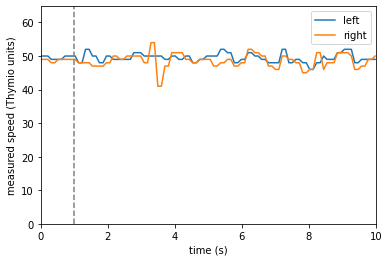

In [51]:
t = np.array(t_list)
v_l = np.array(left_list)
v_r = np.array(right_list)

keep = t > SKIP                   
v_l, v_r = v_l[keep], v_r[keep]
print(v_l.mean(), v_r.mean(), np.var(v_l), np.var(v_r))

plt.plot(t, left_list, label="left")
plt.plot(t, right_list, label="right")
plt.axvline(SKIP, color="gray", linestyle="--")
plt.xlabel("time (s)"); plt.ylabel("measured speed (Thymio units)")
plt.xlim(0, DURATION)
plt.ylim(0, 1.2 * max(max(left_list), max(right_list)))
plt.legend(); plt.show()

24.5, 24.55

96.94186046511628 98.30232558139535 49.17103839913467 106.00162249864792


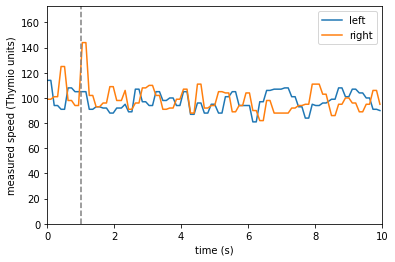

In [55]:
t = np.array(t_list)
v_l = np.array(left_list)
v_r = np.array(right_list)

keep = t > SKIP                   
v_l, v_r = v_l[keep], v_r[keep]
print(v_l.mean(), v_r.mean(), np.var(v_l), np.var(v_r))

plt.plot(t, left_list, label="left")
plt.plot(t, right_list, label="right")
plt.axvline(SKIP, color="gray", linestyle="--")
plt.xlabel("time (s)"); plt.ylabel("measured speed (Thymio units)")
plt.xlim(0, DURATION)
plt.ylim(0, 1.2 * max(max(left_list), max(right_list)))
plt.legend(); plt.show()

In [ ]:
d_l, d_r = 36.8, 36.4
d=(d_l+d_r)/2
d/10/

3.6599999999999993

In [35]:
t = np.array(t_list)
v_l = np.array(left_list)
v_r = np.array(right_list)

keep = t > SKIP                   
v_l, v_r = v_l[keep], v_r[keep]

In [41]:
v_l.mean(), v_r.mean(), np.var(v_l), np.var(v_r)

(49.0, 50.0, 0.0, 0.0)

In [37]:
len(t), len(v_l), len(v_r)

(3338925, 3338925, 3338925)

In [18]:
# t = 10s, TARGET = 50
t0 = np.array(t_list)
v_l0 = np.array(left_list)
v_r0 = np.array(right_list)

keep = t0 > SKIP
v_l0, v_r0 = v_l0[keep], v_r0[keep]

In [19]:
v_l0.mean(), v_r0.mean()

(50.12643678160919, 48.62068965517241)

samples used: 79
left : mean 99.0 units, var 29.2 units^2 -> 5.39 (mm/s)^2
right: mean 98.9 units, var 40.3 units^2 -> 7.46 (mm/s)^2


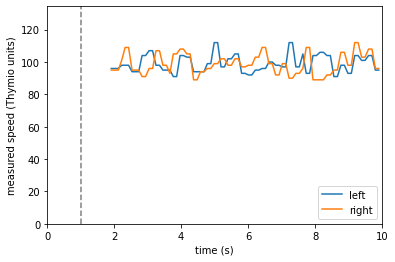

In [ ]:
t = np.array(t_list)
v_l = np.array(left_list)
v_r = np.array(right_list)

keep = t > SKIP                   
v_l, v_r = v_l[keep], v_r[keep]

var_l_units = np.var(v_l)
var_r_units = np.var(v_r)
var_l = var_l_units * SPEED_FACTOR**2   
var_r = var_r_units * SPEED_FACTOR**2

print(f"samples used: {keep.sum()}")
print(f"left : mean {v_l.mean():.1f} units, var {var_l_units:.1f} units^2 -> {var_l:.2f} (mm/s)^2")
print(f"right: mean {v_r.mean():.1f} units, var {var_r_units:.1f} units^2 -> {var_r:.2f} (mm/s)^2")

M = np.diag([var_r, var_l])

plt.plot(t, left_list, label="left")
plt.plot(t, right_list, label="right")
plt.axvline(SKIP, color="gray", linestyle="--")
plt.xlabel("time (s)"); plt.ylabel("measured speed (Thymio units)")
plt.xlim(0, DURATION)
plt.ylim(0, 1.2 * max(max(left_list), max(right_list)))
plt.legend(); plt.show()

samples used: 56
left : mean 99.9 units, var 47.0 units^2 -> 8.69 (mm/s)^2
right: mean 99.0 units, var 53.3 units^2 -> 9.85 (mm/s)^2


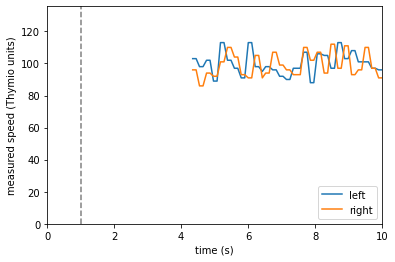

In [25]:
t = np.array(t_list)
v_l = np.array(left_list)
v_r = np.array(right_list)

keep = t > SKIP                   
v_l, v_r = v_l[keep], v_r[keep]

var_l_units = np.var(v_l)
var_r_units = np.var(v_r)
var_l = var_l_units * SPEED_FACTOR**2   
var_r = var_r_units * SPEED_FACTOR**2

print(f"samples used: {keep.sum()}")
print(f"left : mean {v_l.mean():.1f} units, var {var_l_units:.1f} units^2 -> {var_l:.2f} (mm/s)^2")
print(f"right: mean {v_r.mean():.1f} units, var {var_r_units:.1f} units^2 -> {var_r:.2f} (mm/s)^2")

M = np.diag([var_r, var_l])

plt.plot(t, left_list, label="left")
plt.plot(t, right_list, label="right")
plt.axvline(SKIP, color="gray", linestyle="--")
plt.xlabel("time (s)"); plt.ylabel("measured speed (Thymio units)")
plt.xlim(0, DURATION)
plt.ylim(0, 1.2 * max(max(left_list), max(right_list)))
plt.legend(); plt.show()

measured distances : 
 - right : 32 cm
 - left : 33 cm

samples used: 81
left : mean 96.8 units, var 41.6 units^2 -> 7.68 (mm/s)^2
right: mean 97.4 units, var 99.2 units^2 -> 18.33 (mm/s)^2


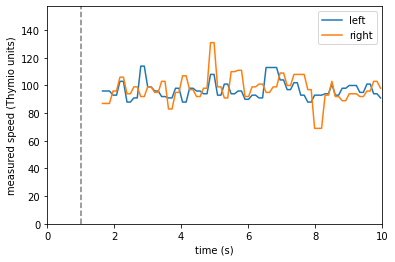

In [29]:
t = np.array(t_list)
v_l = np.array(left_list)
v_r = np.array(right_list)

keep = t > SKIP                   
v_l, v_r = v_l[keep], v_r[keep]

var_l_units = np.var(v_l)
var_r_units = np.var(v_r)
var_l = var_l_units * SPEED_FACTOR**2   
var_r = var_r_units * SPEED_FACTOR**2

print(f"samples used: {keep.sum()}")
print(f"left : mean {v_l.mean():.1f} units, var {var_l_units:.1f} units^2 -> {var_l:.2f} (mm/s)^2")
print(f"right: mean {v_r.mean():.1f} units, var {var_r_units:.1f} units^2 -> {var_r:.2f} (mm/s)^2")

M = np.diag([var_r, var_l])

plt.plot(t, left_list, label="left")
plt.plot(t, right_list, label="right")
plt.axvline(SKIP, color="gray", linestyle="--")
plt.xlabel("time (s)"); plt.ylabel("measured speed (Thymio units)")
plt.xlim(0, DURATION)
plt.ylim(0, 1.2 * max(max(left_list), max(right_list)))
plt.legend(); plt.show()

measured distances : 
 - right : 31.7 cm
 - left : 32.5 cm

In [31]:
v_l, v_r

(array([ 96,  96,  96,  93,  93, 103, 103,  88,  88,  91,  91, 114, 114,
         99,  99,  96,  96,  92,  92,  91,  91,  98,  98,  88,  88,  98,
         98,  96,  96,  94,  94, 108, 108,  93,  93, 101, 101,  94,  94,
         96,  96,  90,  90,  93,  93,  91,  91, 113, 113, 113, 113, 104,
        104,  97,  97, 102, 102,  93,  93,  88,  88,  93,  93,  93,  94,
         94, 101,  93,  93,  98,  98, 100, 100, 100,  95,  95, 101, 101,
         94,  94,  91]),
 array([ 87,  87,  87,  96,  96, 106, 106,  94,  94,  99,  99,  92,  92,
         99,  99,  95,  95, 103, 103,  83,  83,  95,  95, 107, 107,  97,
         97,  92,  92,  98,  98, 131, 131,  99,  99,  91,  91, 110, 110,
        111, 111,  92,  92,  99,  99, 101, 101,  95,  95,  99,  99, 109,
        109, 100, 100, 108, 108, 108, 108,  97,  97,  69,  69,  69,  93,
         93, 103,  92,  92,  89,  89,  94,  94,  94,  92,  92,  96,  96,
        103, 103,  98]))

In [22]:
v_l.mean(), v_r.mean()

(98.9873417721519, 98.88607594936708)

In [59]:
await node.unlock()